# Clustering Track: Hotel Booking Demand
**Dataset**: Hotel Booking Demand (Antonio, Almeida & Nunes, 2019), `hotel_bookings.csv`
<br>
**Dataset Overview:**
The dataset describes 119,390 bookings made at a city hotel and a resort hotel in Portugal between July 2015 and August 2017. Each row is one booking with 32 columns covering lead time, length of stay, guests, market segment, deposit type, price (`adr`) and the final booking status.
Source: the original data paper in *Data in Brief* (2019), copied from the TidyTuesday mirror (`rfordatascience/tidytuesday`, 2020-02-11).

**Objective:** group similar bookings using only their characteristics, with no labels. The columns that reveal the outcome of a booking (`is_canceled`, `reservation_status`, `reservation_status_date`) are kept out of the clustering inputs and are only used after clustering to describe the groups.

This notebook runs the two clustering algorithms required by the Capstone Guidelines: K-Means and Agglomerative Hierarchical Clustering.

## Section A - Dataset & EDA
### A1: Dataset loading & audit

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, dendrogram

%matplotlib inline
%config InlineBackend.figure_format = 'retina'
plt.rcParams['figure.max_open_warning'] = 50

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('colorblind')
plt.rcParams['figure.dpi'] = 110

SEED = 42

df = pd.read_csv('../data/hotel_bookings.csv')
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [2]:
df.info()
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


In [3]:
print("Duplicate rows:", df.duplicated().sum())
df.isnull().sum()[lambda s: s > 0]

Duplicate rows: 31994


children         4
country        488
agent        16340
company     112593
dtype: int64

**Observation (Audit):** The file has 119,390 rows and 32 columns, matching the published dataset. `company` is missing in 94% of rows and `agent` in 14%; both are booking-agency ID codes rather than measurements, so they are not useful for distance-based clustering. `country` has 488 missing values and 177 distinct codes, and `children` has 4 missing values. There are 31,994 exact duplicate rows.

### A2 & A3: EDA Visualisations & Insight Commentary

In [4]:
df.describe(include='object').T

,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613


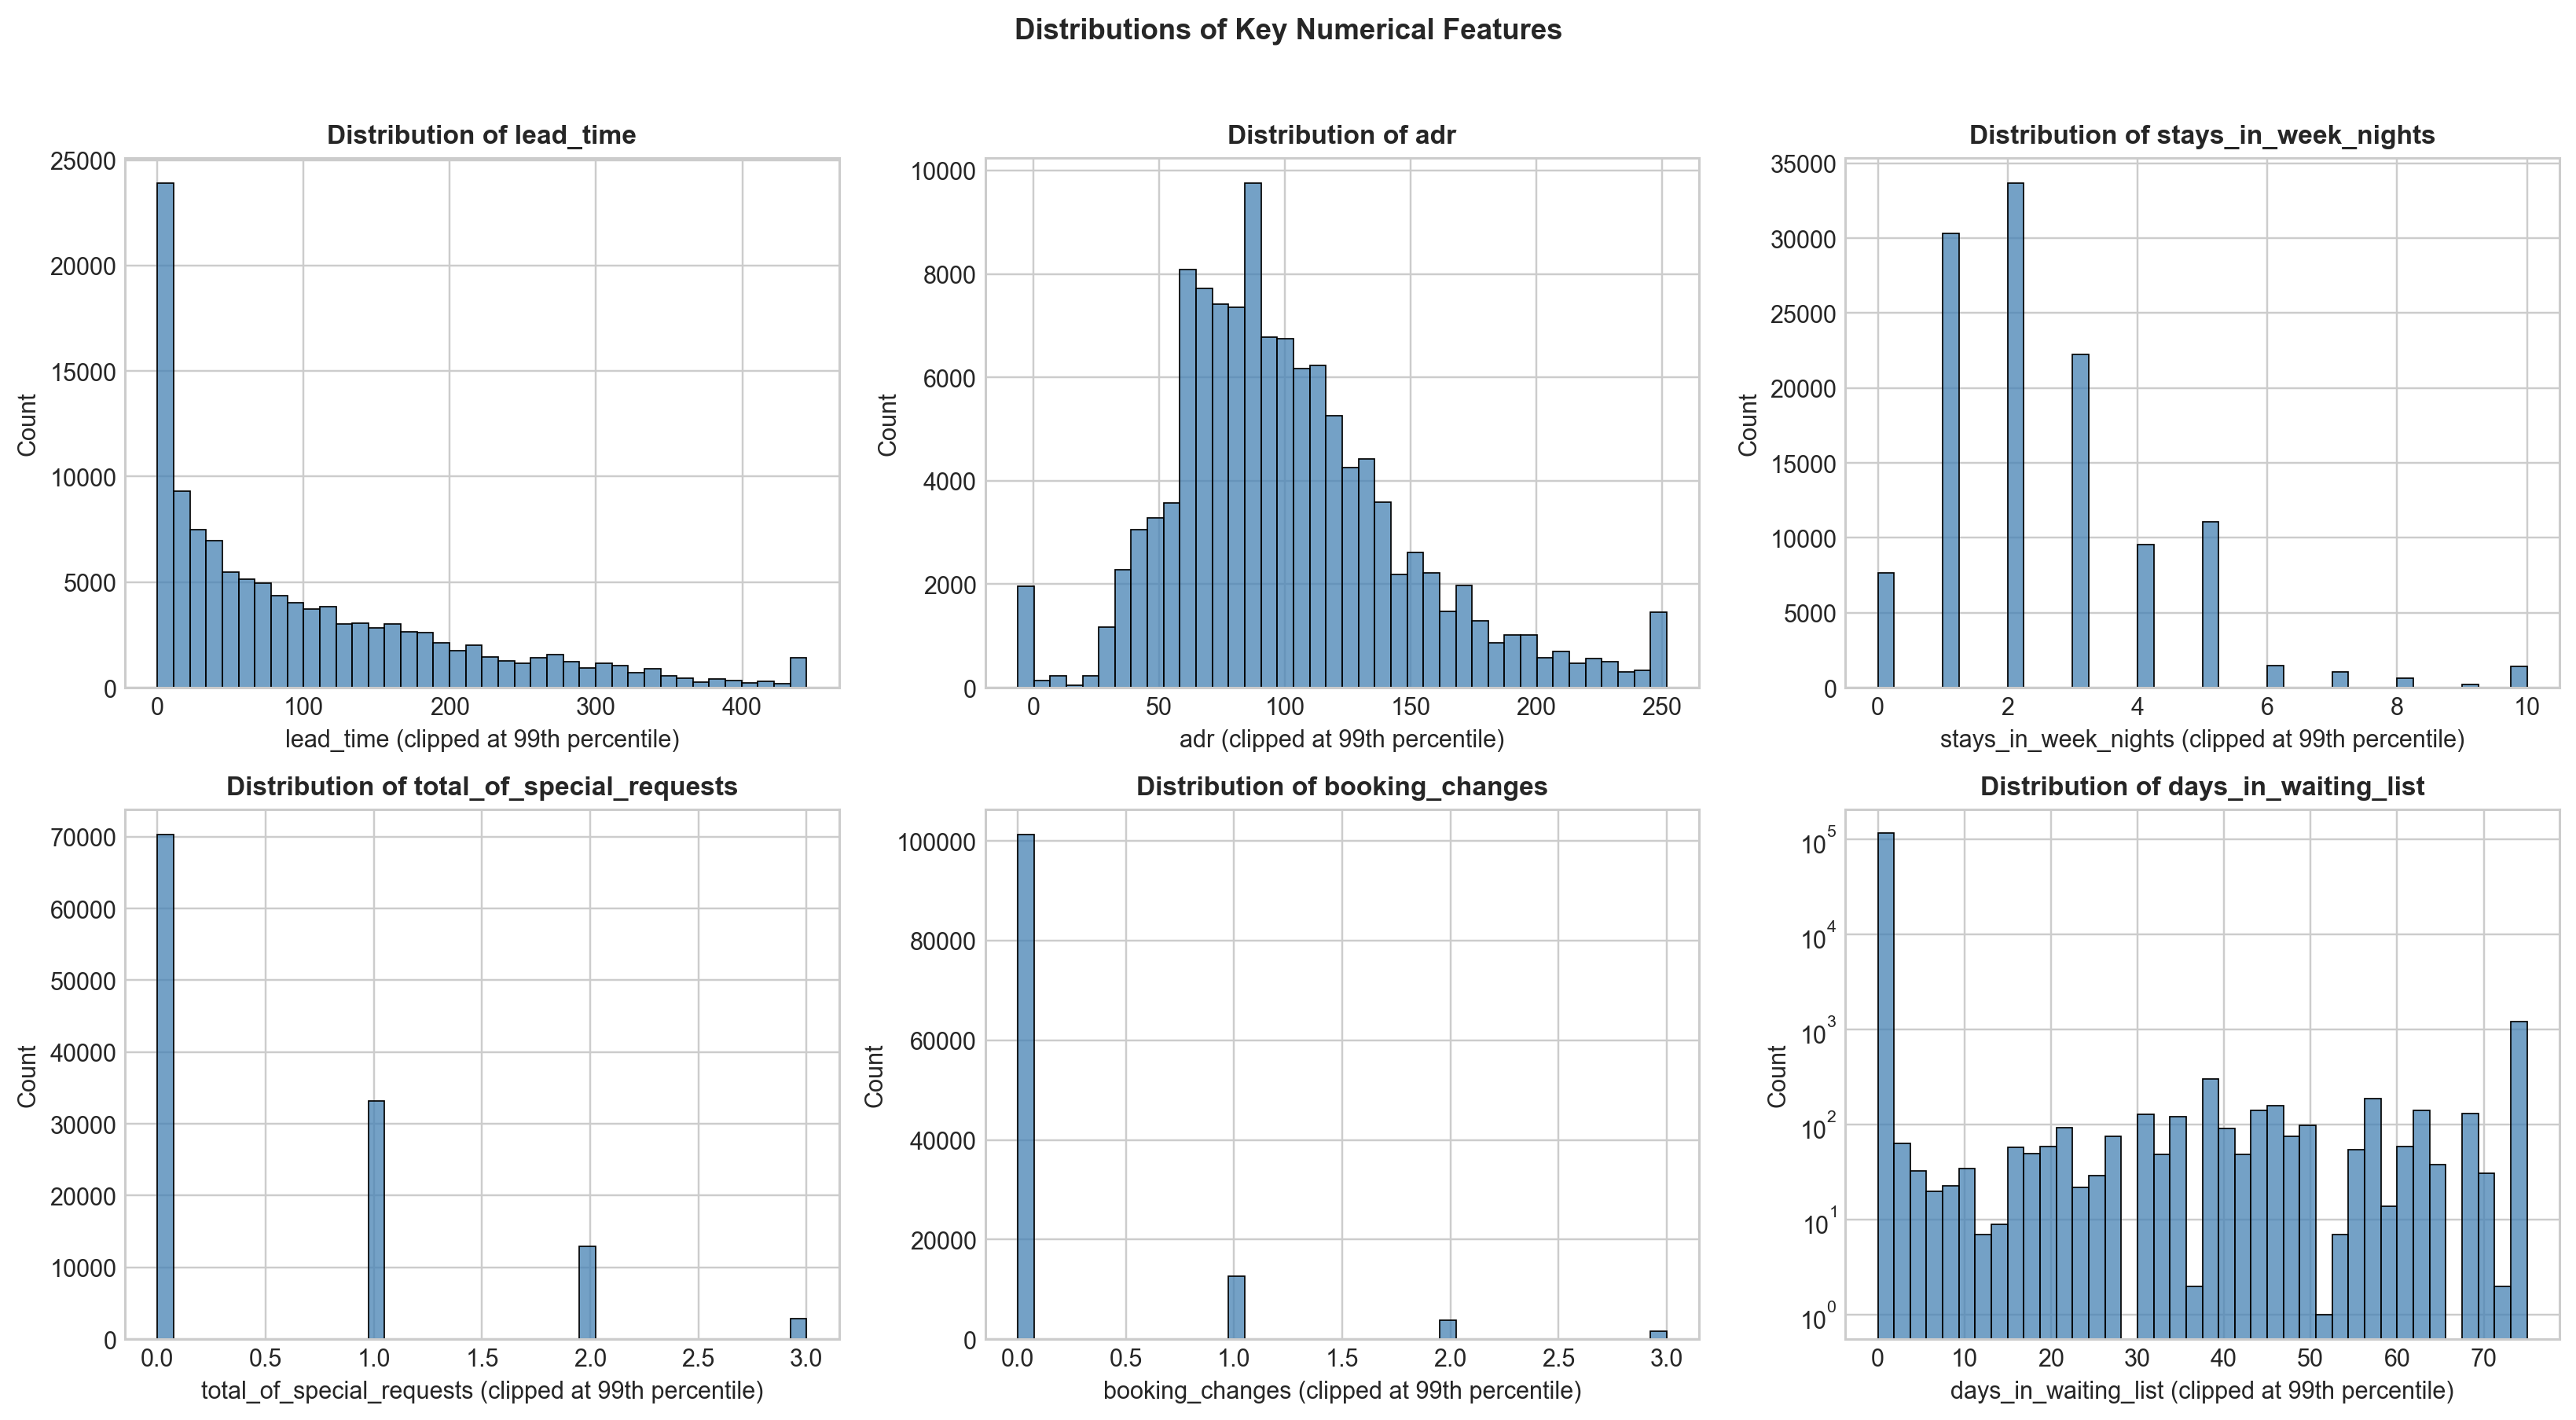

,Skewness
babies,24.65
previous_cancellations,24.46
previous_bookings_not_canceled,23.54
adults,18.32
days_in_waiting_list,11.94
adr,10.53
booking_changes,6.00
is_repeated_guest,5.33
required_car_parking_spaces,4.16
children,4.11


In [5]:
skewed_features = ['lead_time', 'adr', 'stays_in_week_nights', 'total_of_special_requests',
                   'booking_changes', 'days_in_waiting_list']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), skewed_features):
    data = df[col].clip(upper=df[col].quantile(0.99))
    sns.histplot(data, bins=40, color='steelblue', edgecolor='black', ax=ax)
    ax.set_title(f"Distribution of {col}", fontsize=11, fontweight='bold')
    ax.set_xlabel(col + " (clipped at 99th percentile)")
    ax.set_ylabel("Count")
axes[1, 2].set_yscale('log')
plt.suptitle("Distributions of Key Numerical Features", y=1.02, fontweight='bold')
plt.tight_layout()
plt.show()

numeric_cols = ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies',
                'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes',
                'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']
df[numeric_cols].skew().round(2).sort_values(ascending=False).to_frame('Skewness')

**Observation (Distributions):** The count-like features are strongly right-skewed. `previous_cancellations`, `previous_bookings_not_canceled`, `babies`, `adults`, `days_in_waiting_list` and `adr` all have skewness above 10, because most bookings have a value of 0 or a typical price and a few are extreme. `lead_time` and `stays_in_week_nights` are skewed less but still have long right tails. Standardising these columns directly would let a few extreme rows dominate the distances, so a log transform is applied before scaling.

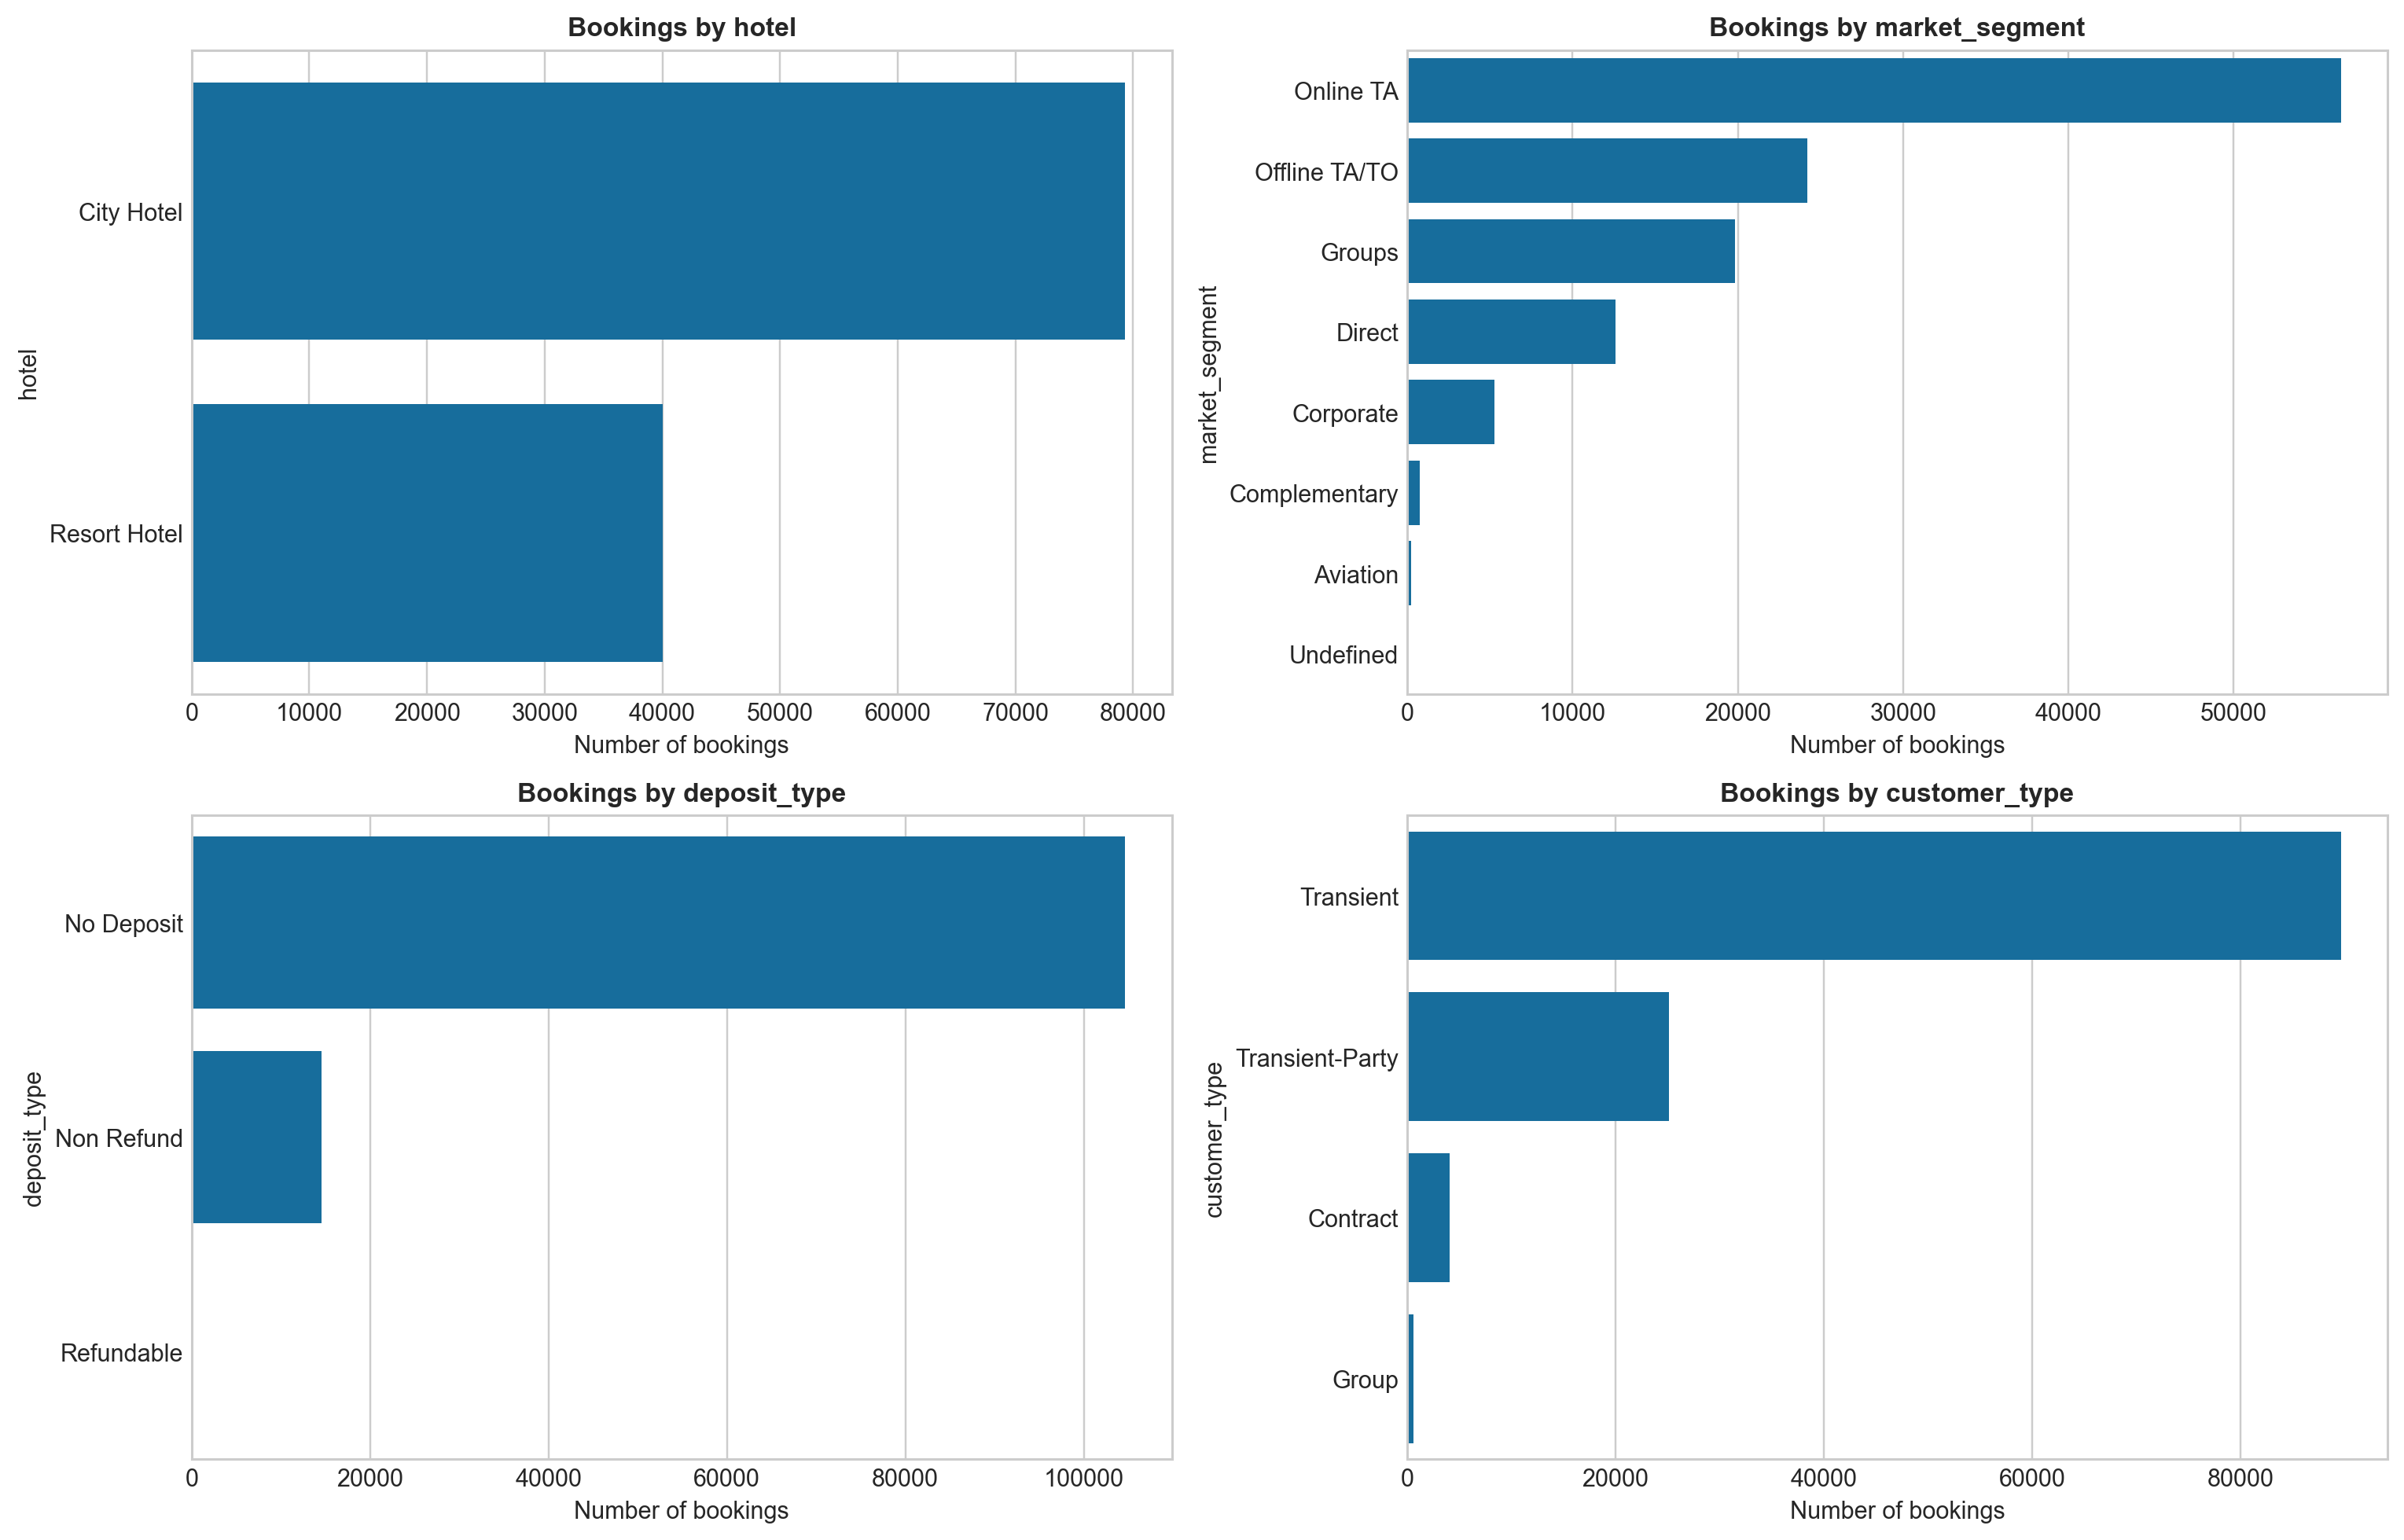

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.flatten(), ['hotel', 'market_segment', 'deposit_type', 'customer_type']):
    order = df[col].value_counts().index
    sns.countplot(y=col, data=df, order=order, ax=ax)
    ax.set_title(f"Bookings by {col}", fontsize=11, fontweight='bold')
    ax.set_xlabel("Number of bookings")
    ax.set_ylabel(col)
plt.tight_layout()
plt.show()

**Observation (Categorical Features):** About two thirds of the bookings are for the City Hotel (66.4%). Online travel agents make up 47.3% of bookings, followed by offline agents (20.3%) and groups (16.6%). `deposit_type` is dominated by `No Deposit` (87.6%) and `customer_type` by `Transient` (75.1%), so a few categories carry most of the rows while the rest are small.

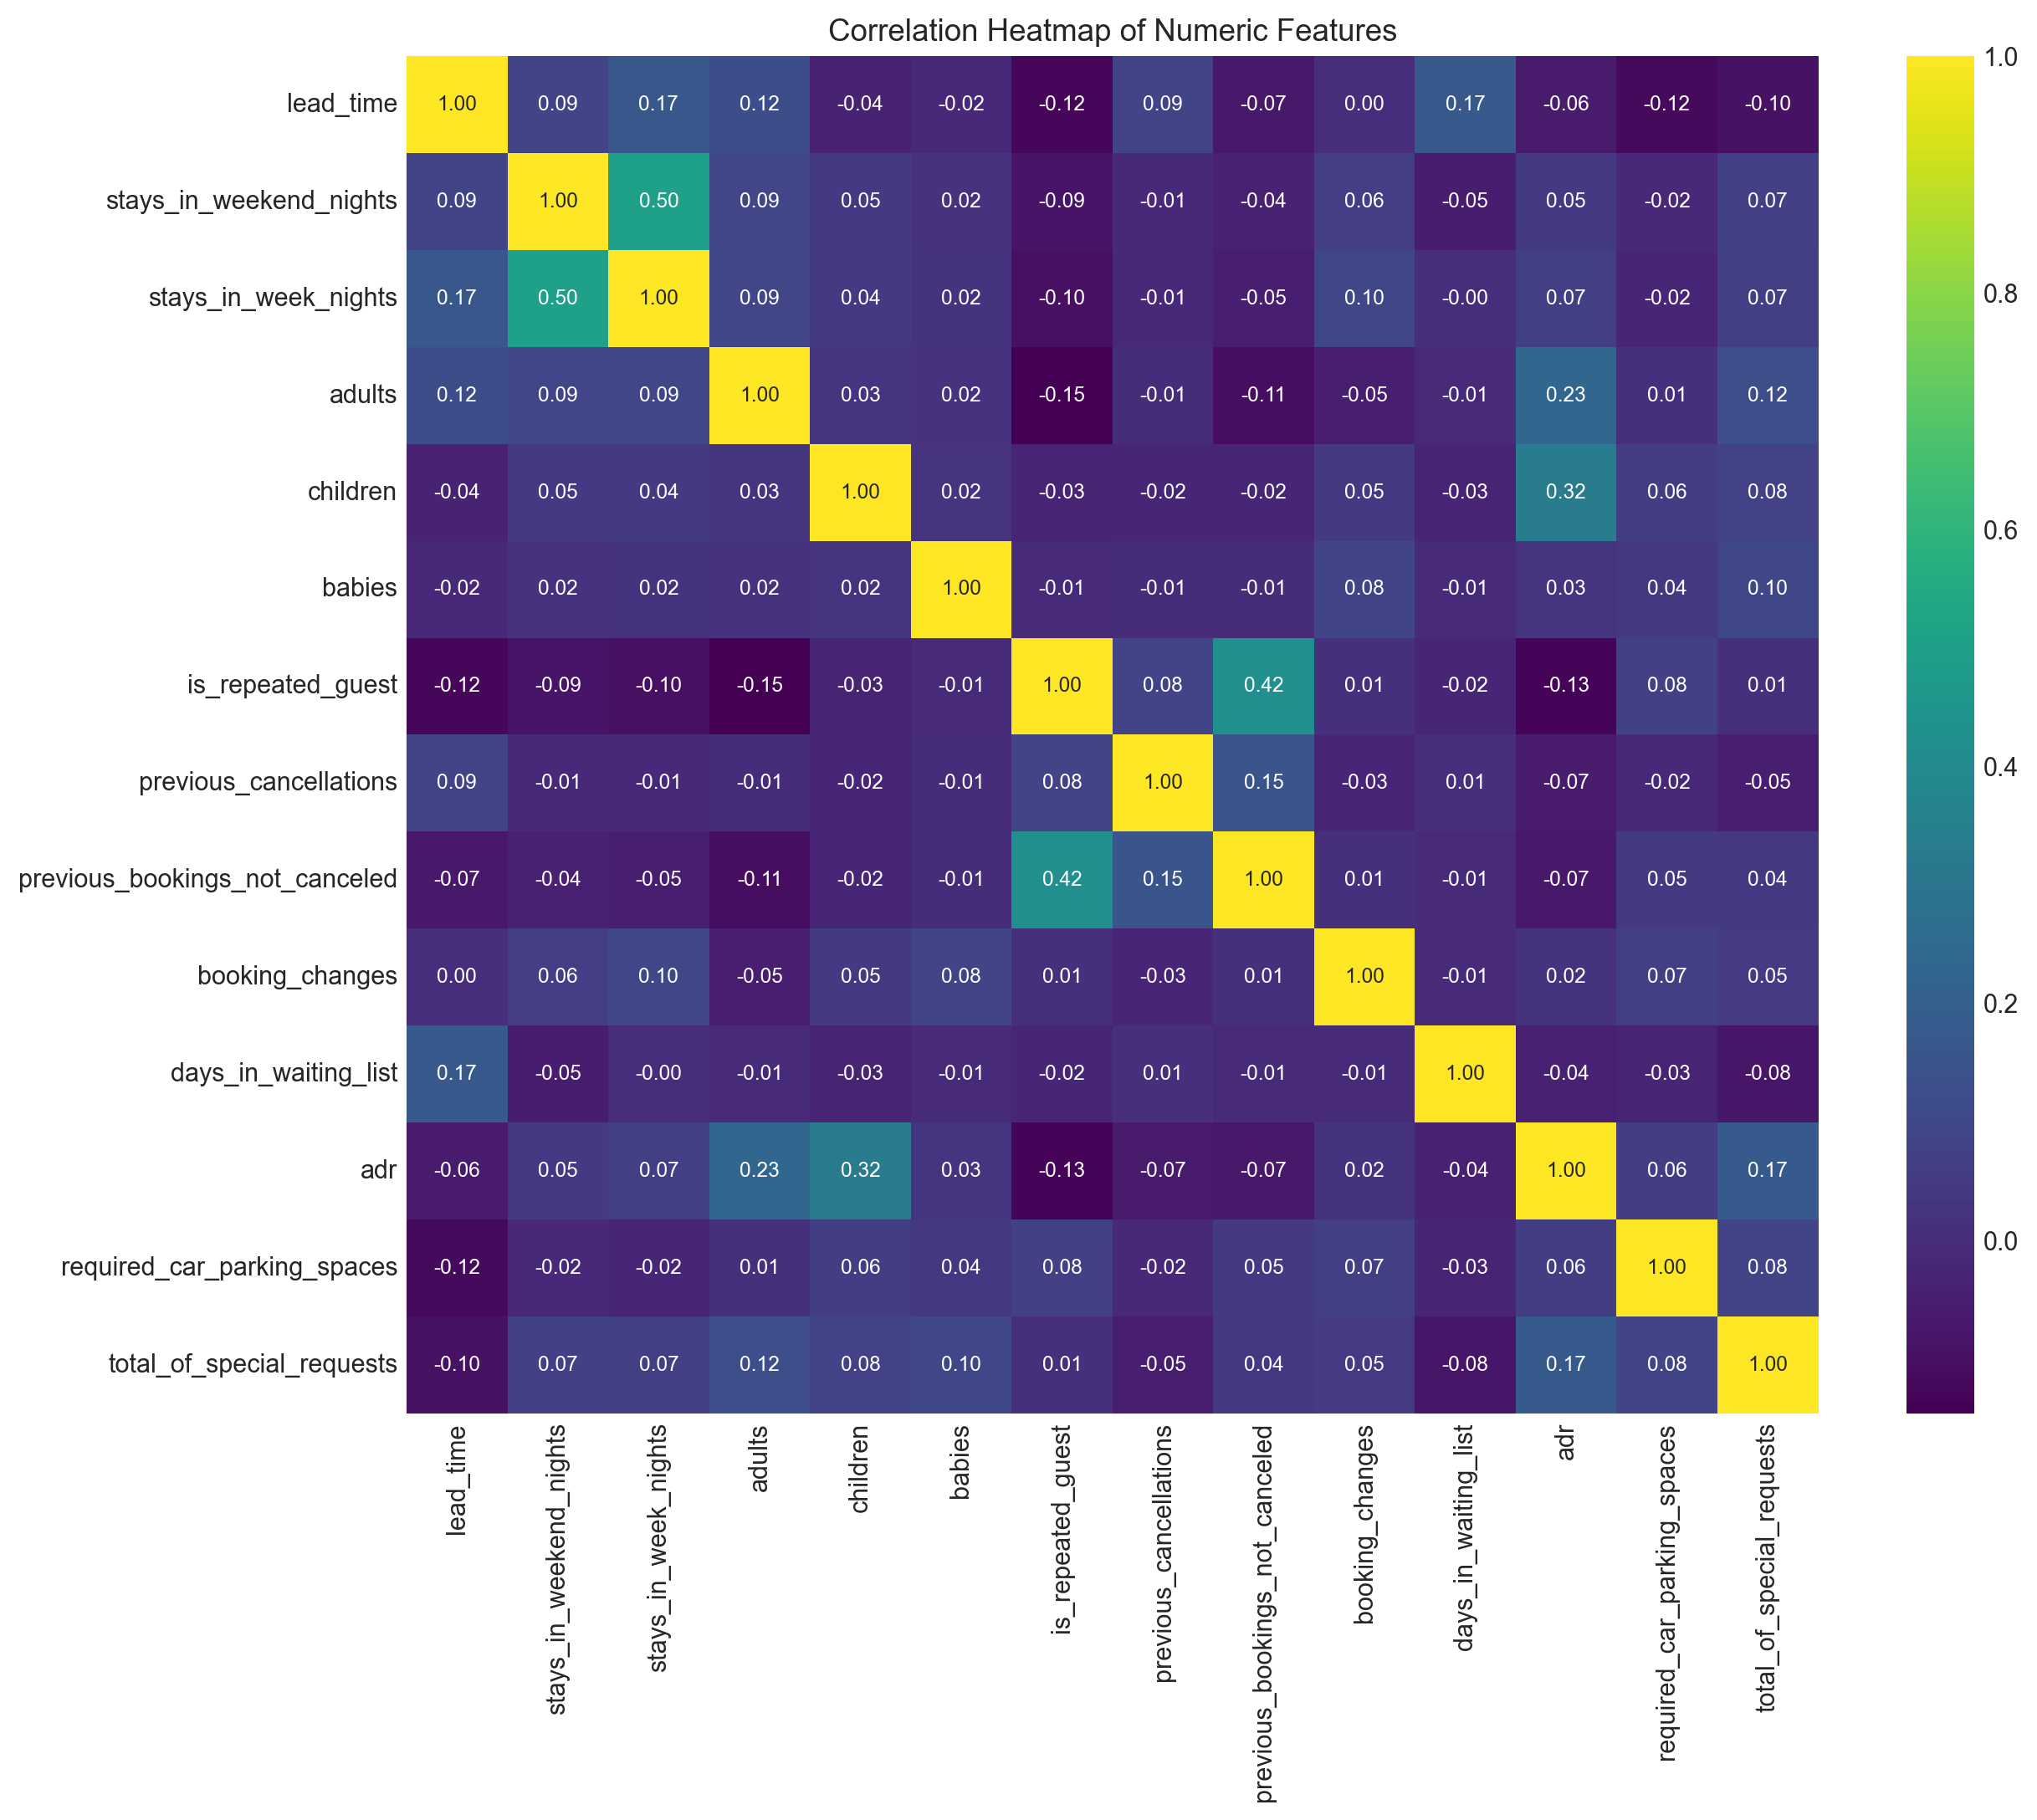

In [7]:
plt.figure(figsize=(12, 10))
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, cmap='viridis', fmt='.2f', annot_kws={'size': 8})
plt.title('Correlation Heatmap of Numeric Features')
plt.tight_layout()
plt.show()

**Observation (Correlation):** Correlations between the booking features are weak to moderate. The largest are `stays_in_weekend_nights` with `stays_in_week_nights` (0.50), `is_repeated_guest` with `previous_bookings_not_canceled` (0.42), which describe the same customer history, and `children` with `adr` (0.32). No pair is strong enough to justify dropping a feature, so all of them are kept.

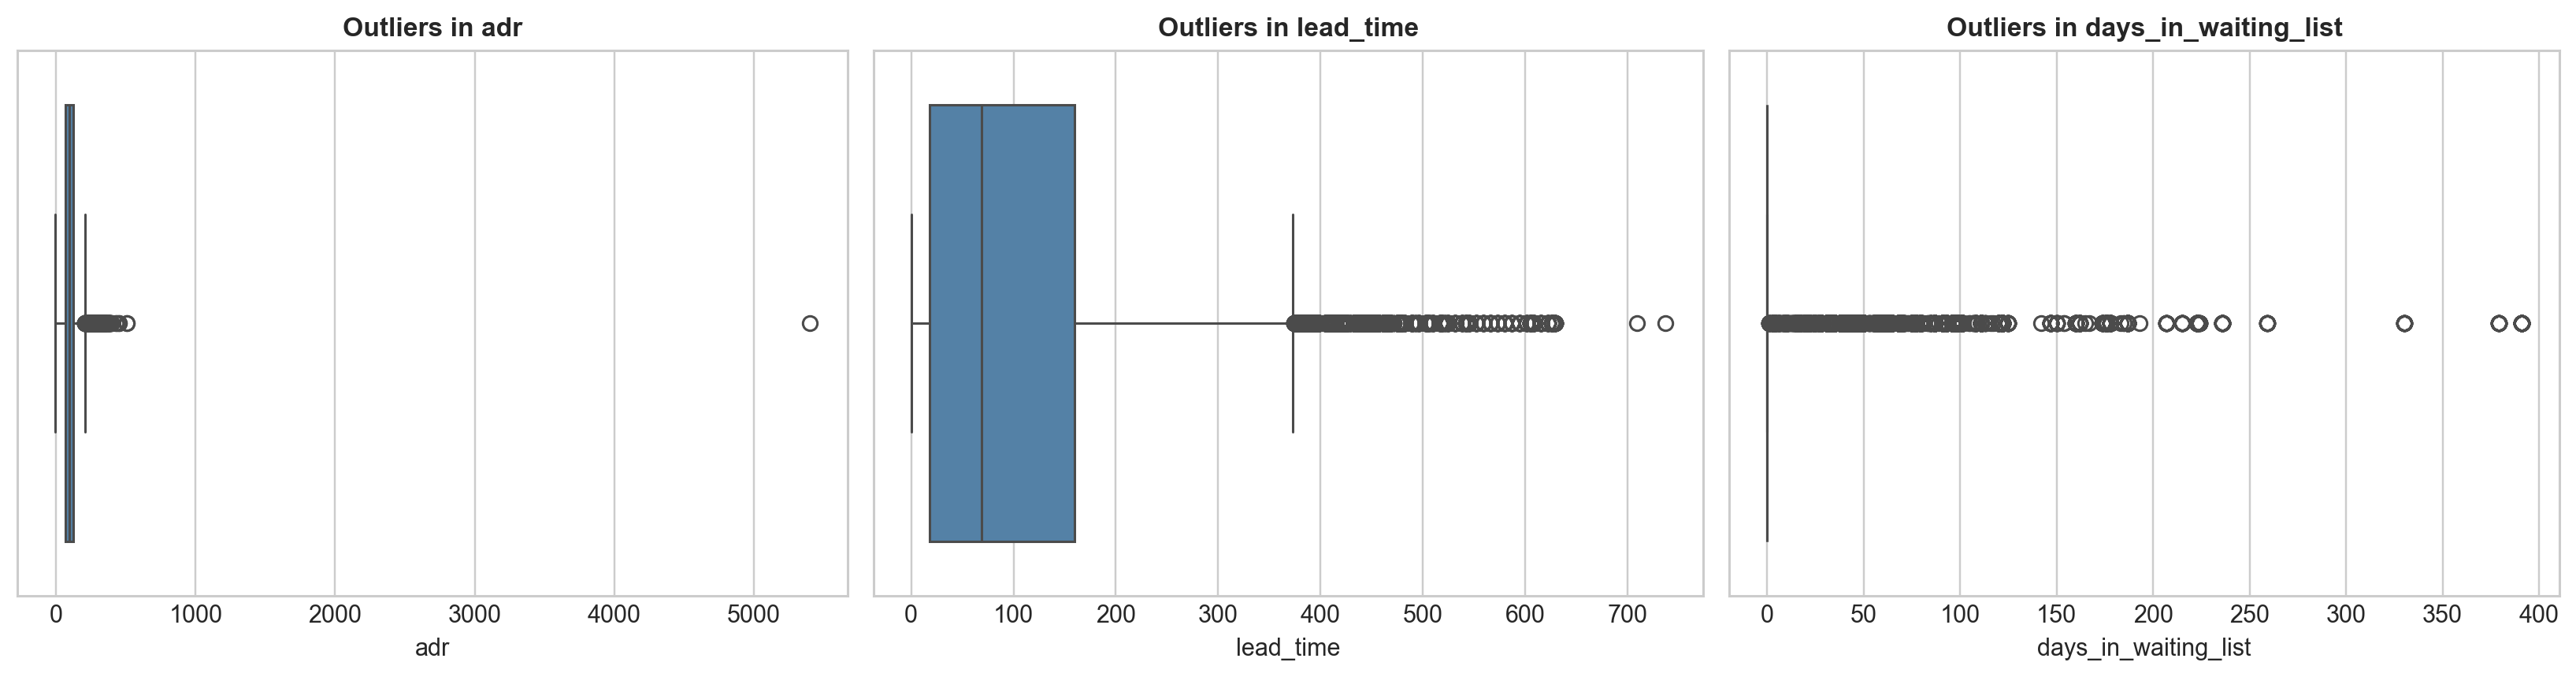

Negative adr: 1
Bookings with zero guests: 180
adr above 1000: 1


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['adr', 'lead_time', 'days_in_waiting_list']):
    sns.boxplot(x=df[col], color='steelblue', ax=ax)
    ax.set_title(f"Outliers in {col}", fontsize=11, fontweight='bold')
    ax.set_xlabel(col)
plt.tight_layout()
plt.show()

print("Negative adr:", (df['adr'] < 0).sum())
print("Bookings with zero guests:", ((df['adults'] + df['children'].fillna(0) + df['babies']) == 0).sum())
print("adr above 1000:", (df['adr'] > 1000).sum())

**Observation (Outliers & Invalid Values):** `adr` has one negative value, one extreme value of 5,400 and a long upper tail; `lead_time` reaches almost two years and `days_in_waiting_list` reaches over 390 days. Most of these are plausible bookings, so they are kept and handled with a log transform rather than removed. The negative price and the 180 bookings with no adults, children or babies are invalid records and are removed during cleaning.

## Section B - Preprocessing & Feature Selection

### B1: Data Cleaning & Feature Selection
- **Duplicates and invalid rows:** exact duplicates, bookings with zero guests and the negative `adr` row are removed.
- **Outcome columns (excluded):** `is_canceled`, `reservation_status` and `reservation_status_date` describe what happened to the booking, so they are never used as clustering inputs. They are stored separately for interpreting the clusters afterwards.
- **Other excluded columns:** `agent` and `company` (ID codes, mostly missing), `country` (177 categories), `assigned_room_type` (decided after booking and tied to the stay outcome) and the arrival date fields (calendar position rather than booking behaviour).
- **Sampling:** hierarchical clustering needs the full pairwise distance matrix, so both algorithms use the same random sample of 15,000 cleaned bookings (`random_state=42`).

In [9]:
df_clean = df.drop_duplicates()
df_clean = df_clean[(df_clean['adults'] + df_clean['children'].fillna(0) + df_clean['babies']) > 0]
df_clean = df_clean[df_clean['adr'] >= 0]
print(f"Rows after cleaning: {len(df_clean):,} (from {len(df):,})")

numeric_features = ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies',
                    'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes',
                    'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']
categorical_features = ['hotel', 'meal', 'market_segment', 'distribution_channel', 'deposit_type',
                        'customer_type', 'reserved_room_type']
skewed_to_log = ['lead_time', 'days_in_waiting_list', 'previous_cancellations',
                 'previous_bookings_not_canceled', 'booking_changes', 'adr']

# Same 15,000 bookings are used for every model
sample = df_clean.sample(n=15000, random_state=SEED).reset_index(drop=True)
X = sample[numeric_features + categorical_features].copy()
X['children'] = X['children'].fillna(0)

# Outcome labels are kept apart and only used after clustering
outcome = sample[['is_canceled', 'reservation_status']]

Rows after cleaning: 87,229 (from 119,390)


### B2: Encoding & Scaling
- **Log transform:** `log1p` is applied to the heavily skewed non-negative columns so extreme bookings do not dominate the distances.
- **Scaling:** `StandardScaler` puts every numeric feature on the same scale, since K-Means and hierarchical clustering are distance based.
- **Encoding:** the seven categorical columns have at most 10 categories each, so they are one-hot encoded. Integer codes would imply an order that does not exist.
- The transformer is fitted on the 15,000-row clustering sample and the same matrix is used for both algorithms.

In [10]:
for col in skewed_to_log:
    X[col] = np.log1p(X[col])

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
])
X_scaled = preprocessor.fit_transform(X)
feature_names = [n.split('__', 1)[1] for n in preprocessor.get_feature_names_out()]

assert not {'is_canceled', 'reservation_status', 'reservation_status_date'} & set(feature_names)
print(f"Final feature matrix: {X_scaled.shape[0]:,} bookings x {X_scaled.shape[1]} features")

Final feature matrix: 15,000 bookings x 48 features


## Section C - K-Means Clustering

### How It Works
K-Means splits the bookings into $k$ groups by repeatedly assigning each booking to its nearest centroid and moving each centroid to the mean of its group. It minimises the **inertia**, the sum of squared distances between every booking and its centroid. Inertia always falls as $k$ grows, so the elbow curve is used to find the point where adding more clusters stops helping much.

### Choosing k
We fit K-Means for $k = 2$ to $10$ (`n_init=10`, `random_state=42`) on `X_scaled` and record inertia, with silhouette and Davies-Bouldin scores as extra evidence.

,k,Inertia,Silhouette,Davies-Bouldin
0,2,221913.623,0.481,1.284
1,3,205847.536,0.101,2.417
2,4,193100.043,0.209,1.467
3,5,176155.063,0.110,1.676
4,6,165114.407,0.125,1.742
5,7,159279.808,0.129,1.772
6,8,143154.246,0.148,1.584
7,9,137748.650,0.129,1.620
8,10,130410.714,0.133,1.542


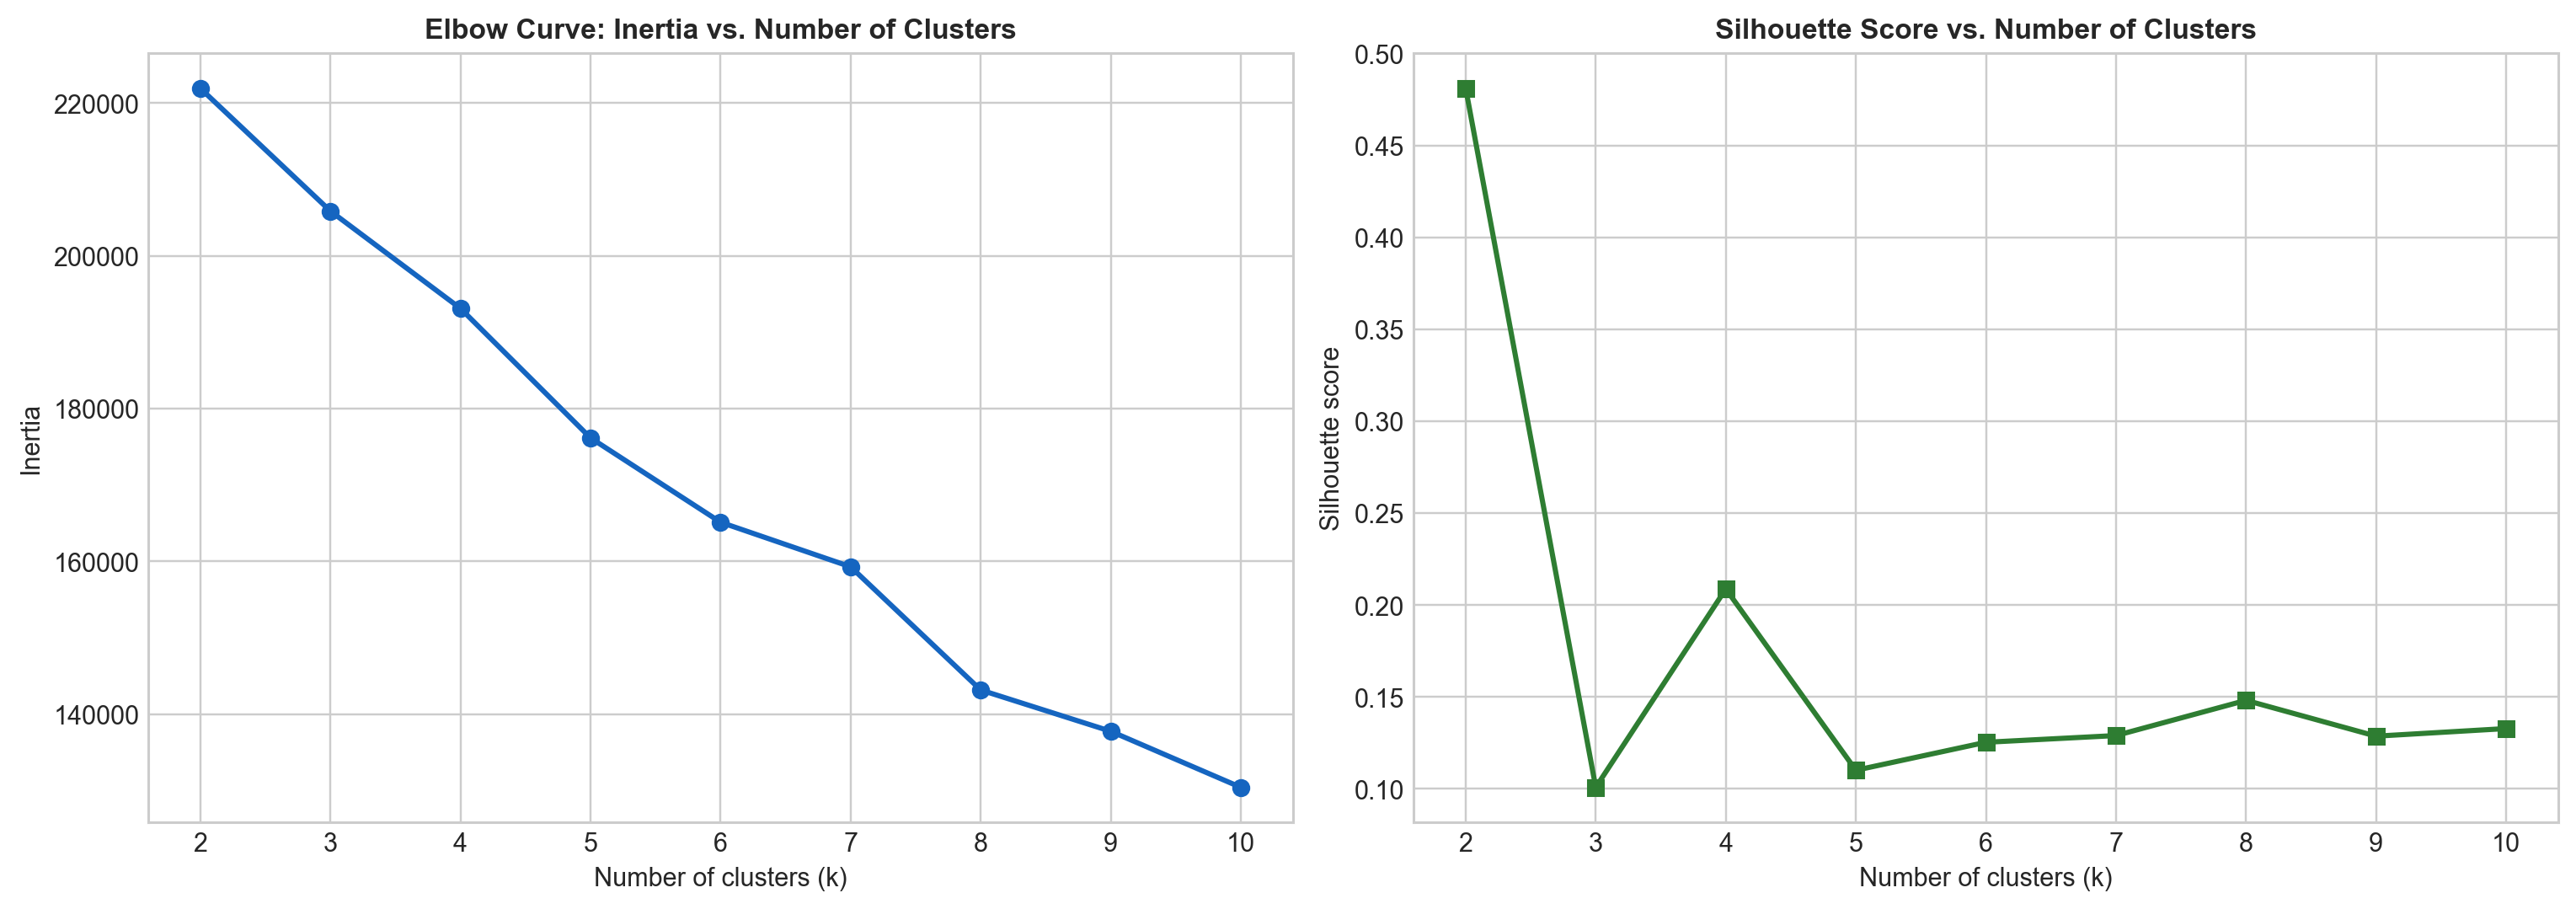

In [11]:
k_values = range(2, 11)
kmeans_search = []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_scaled)
    kmeans_search.append({
        'k': k,
        'Inertia': km.inertia_,
        'Silhouette': silhouette_score(X_scaled, km.labels_),
        'Davies-Bouldin': davies_bouldin_score(X_scaled, km.labels_)
    })
kmeans_search = pd.DataFrame(kmeans_search)
display(kmeans_search.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(kmeans_search['k'], kmeans_search['Inertia'], marker='o', color='#1565c0', lw=2)
axes[0].set_title("Elbow Curve: Inertia vs. Number of Clusters", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(kmeans_search['k'], kmeans_search['Silhouette'], marker='s', color='#2e7d32', lw=2)
axes[1].set_title("Silhouette Score vs. Number of Clusters", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")

plt.tight_layout()
plt.show()

**Observation (Elbow Curve):** Inertia falls steadily from 221,914 at $k=2$ to 130,411 at $k=10$ without a sharp bend, so the elbow curve alone does not give a clear $k$. The silhouette score is highest at $k=2$ (0.481), but the cross-tab below shows that this split only isolates 626 bookings, of which 94% are repeated guests, and leaves 96% of the data in one cluster. From $k=3$ onwards the silhouette is best at $k=4$ (0.209, against 0.101 to 0.148 for the others) and the Davies-Bouldin index is also lowest there (1.467). We therefore use $k=4$, while noting that the evidence for any particular $k$ is weak.

In [12]:
# What does the k=2 solution separate?
labels_k2 = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit_predict(X_scaled)
pd.crosstab(labels_k2, sample['is_repeated_guest'], rownames=['k=2 cluster'])

is_repeated_guest,0,1
k=2 cluster,,
0,14372,2
1,40,586


### Final K-Means Model
We fit the final model with $k = 4$ and store the labels.

In [13]:
K_FINAL = 4
kmeans = KMeans(n_clusters=K_FINAL, n_init=10, random_state=SEED).fit(X_scaled)
labels_km = kmeans.labels_

print("K-Means cluster sizes:")
display(pd.Series(labels_km).value_counts().sort_index().to_frame('Bookings').assign(Share=lambda s: (s['Bookings'] / len(labels_km) * 100).round(1)))

km_metrics = {
    'Silhouette': silhouette_score(X_scaled, labels_km),
    'Davies-Bouldin': davies_bouldin_score(X_scaled, labels_km),
    'Calinski-Harabasz': calinski_harabasz_score(X_scaled, labels_km)
}
km_metrics

K-Means cluster sizes:


,Bookings,Share
0,1398,9.3
1,12807,85.4
2,624,4.2
3,171,1.1


{'Silhouette': 0.20868646656828588,
 'Davies-Bouldin': 1.467310919899367,
 'Calinski-Harabasz': 1469.0308900798739}

**Observation (K-Means):** The four clusters are very uneven: 12,807 bookings (85.4%) in cluster 1, 1,398 (9.3%) in cluster 0, 624 (4.2%) in cluster 2 and 171 (1.1%) in cluster 3. The scores are Silhouette 0.2087, Davies-Bouldin 1.4673 and Calinski-Harabasz 1,469.03. A silhouette around 0.2 means the clusters overlap considerably.

### PCA Visualisation
PCA is only used to draw the clusters in two dimensions. Both algorithms are fitted on the full `X_scaled` matrix, not on the two components.

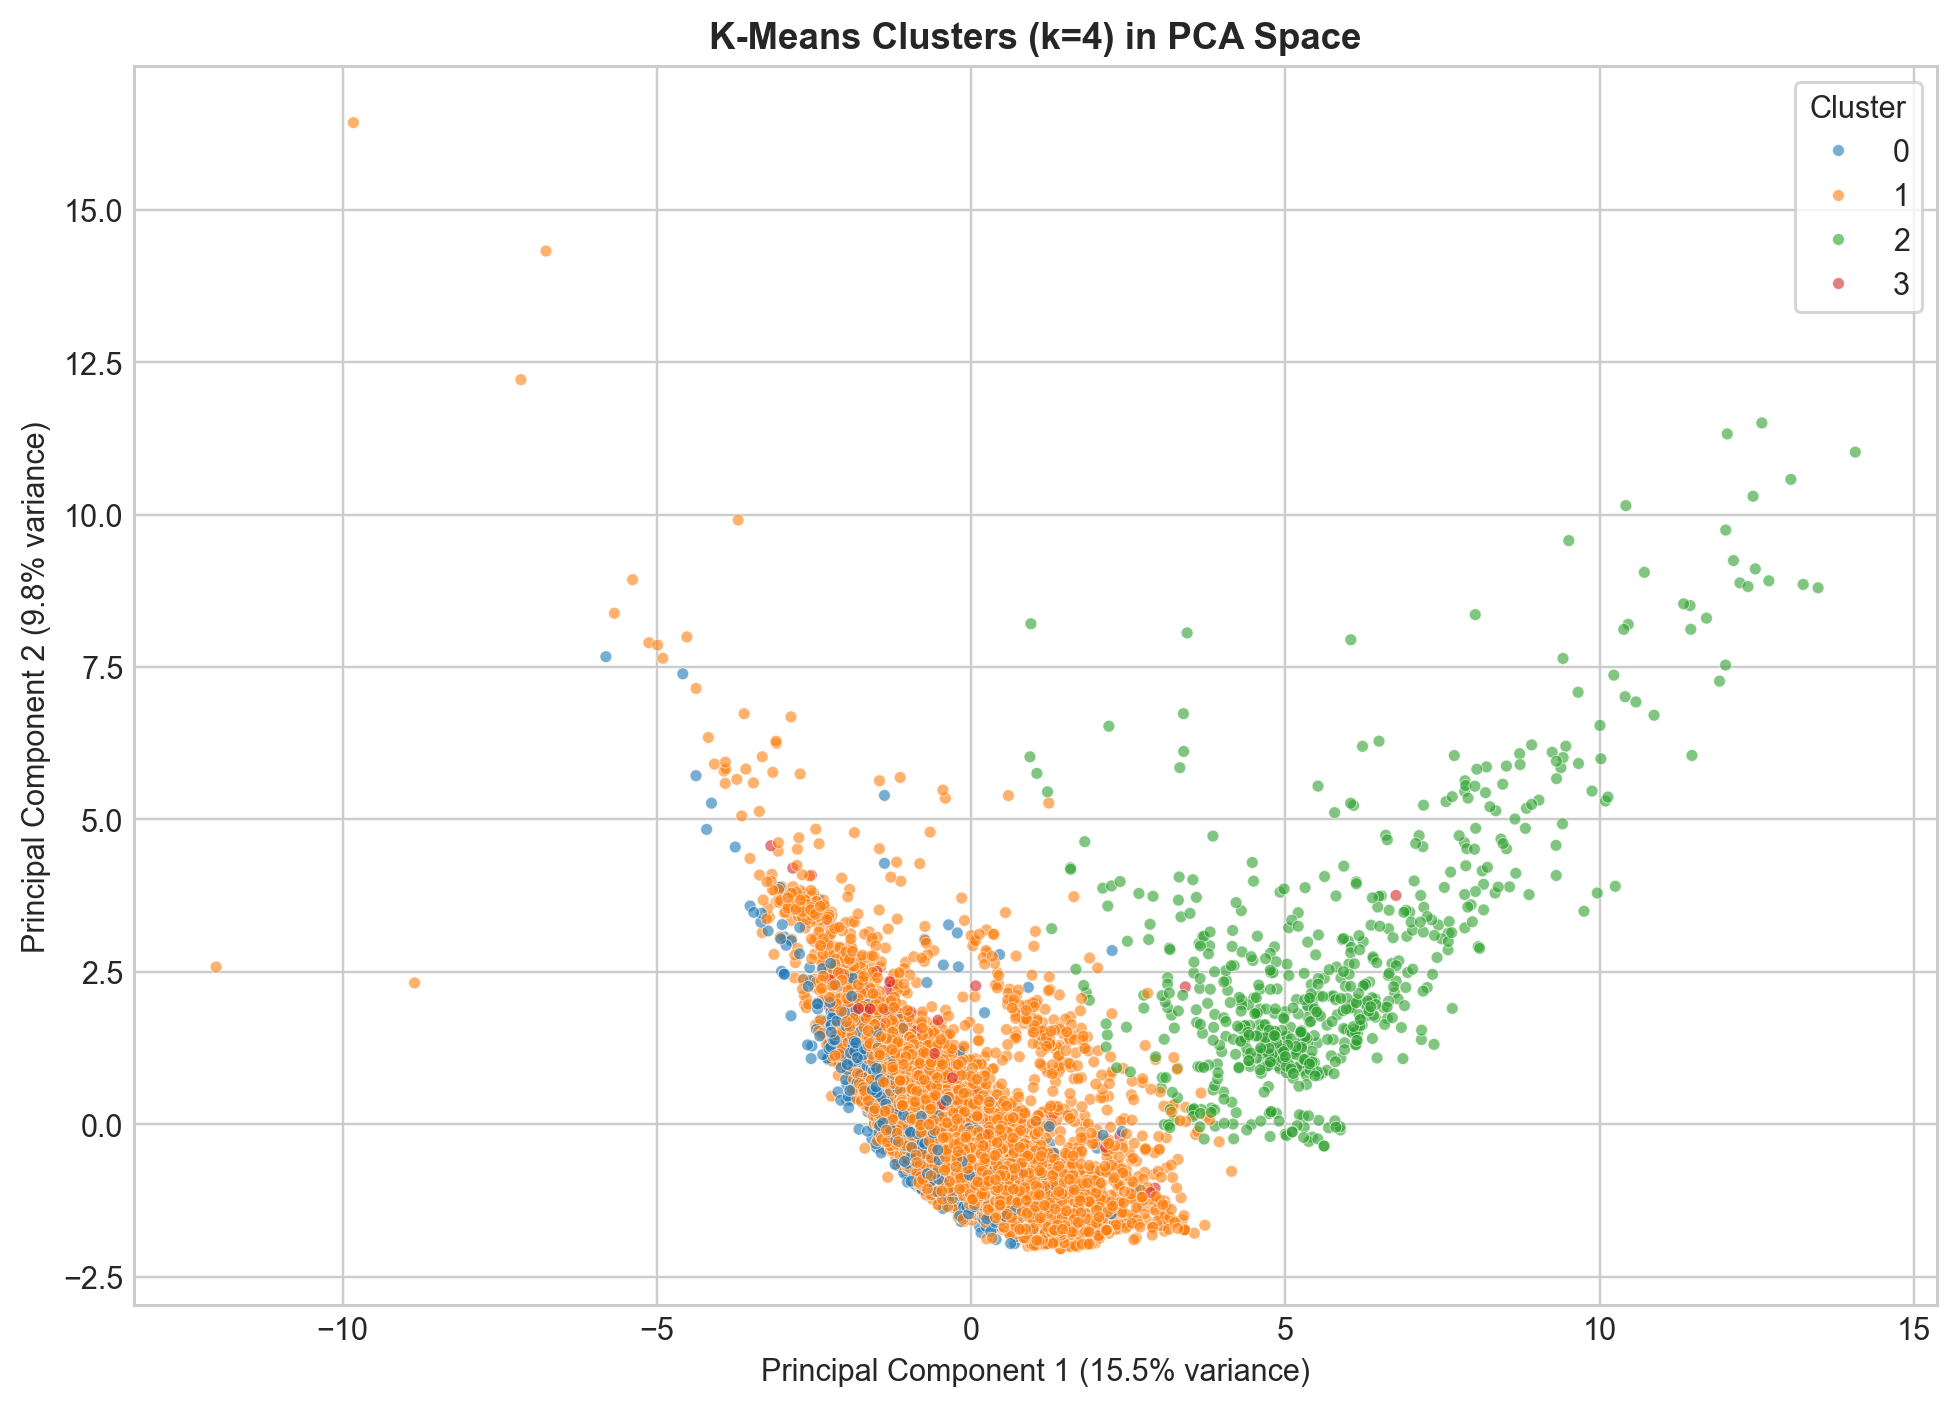

In [14]:
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)
pc1, pc2 = pca.explained_variance_ratio_ * 100

def plot_pca_clusters(labels, title):
    plt.figure(figsize=(9, 6.5))
    sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels, palette='tab10', s=15, alpha=0.6, legend='full')
    plt.title(title, fontsize=12, fontweight='bold')
    plt.xlabel(f"Principal Component 1 ({pc1:.1f}% variance)")
    plt.ylabel(f"Principal Component 2 ({pc2:.1f}% variance)")
    plt.legend(title='Cluster', frameon=True)
    plt.tight_layout()
    plt.show()

plot_pca_clusters(labels_km, "K-Means Clusters (k=4) in PCA Space")

**Observation (K-Means PCA):** The first two components explain only 25.3% of the variance (15.5% and 9.8%), so the plot is a partial view. Cluster 2, the repeated-guest group, forms a separate band on the right. Clusters 0, 1 and 3 overlap heavily in this projection, which fits the low silhouette score.

## Section D - Agglomerative Hierarchical Clustering

### How It Works
Agglomerative clustering starts with every booking as its own cluster and repeatedly merges the two closest clusters until the wanted number is left. The linkage decides how the distance between two clusters is measured:
- **Ward:** merge the pair that increases the within-cluster variance the least (needs Euclidean distance).
- **Complete:** distance between the two farthest members.
- **Average:** mean distance between all pairs of members.

### Choosing the Linkage and Number of Clusters
We compare the three linkages for $2$ to $6$ clusters on the same `X_scaled` matrix (Euclidean distance, all 15,000 bookings).

In [15]:
linkage_search = []
for link in ['ward', 'complete', 'average']:
    for n in range(2, 7):
        lab = AgglomerativeClustering(n_clusters=n, linkage=link).fit_predict(X_scaled)
        linkage_search.append({
            'Linkage': link,
            'Clusters': n,
            'Silhouette': silhouette_score(X_scaled, lab),
            'Davies-Bouldin': davies_bouldin_score(X_scaled, lab),
            'Calinski-Harabasz': calinski_harabasz_score(X_scaled, lab),
            'Smallest cluster': np.bincount(lab).min()
        })
linkage_search = pd.DataFrame(linkage_search)
linkage_search.round(3)

,Linkage,Clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz,Smallest cluster
0,ward,2,0.431,1.893,1518.600,980
1,ward,3,0.442,1.561,1350.610,171
2,ward,4,0.453,1.378,1345.444,142
3,ward,5,0.243,1.420,1343.823,142
4,ward,6,0.221,1.460,1355.511,142
5,complete,2,0.866,0.236,179.458,2
6,complete,3,0.819,0.199,114.585,1
7,complete,4,0.702,0.421,302.085,1
8,complete,5,0.701,0.422,247.458,1
9,complete,6,0.544,0.500,419.300,1


**Observation (Linkage Comparison):** `complete` and `average` linkage give the highest silhouette scores (up to 0.866) and the lowest Davies-Bouldin values, but their smallest cluster has only 1 or 2 bookings and their Calinski-Harabasz scores are very low (102 to 419 against about 1,345 for Ward). They are simply cutting off a few extreme bookings, so those scores are misleading. Ward linkage gives clusters of at least 142 bookings, and its silhouette is highest at 4 clusters (0.453) with the lowest Davies-Bouldin value (1.378) among its settings. We use Ward with 4 clusters, which also matches the $k$ used for K-Means.

### Dendrogram
A scikit-learn fit does not return the merge tree, so the dendrogram is built with SciPy's `linkage` (Ward, Euclidean) on a random subset of 1,000 of the 15,000 bookings. It only illustrates the hierarchy of that subset; the clustering itself uses all 15,000.

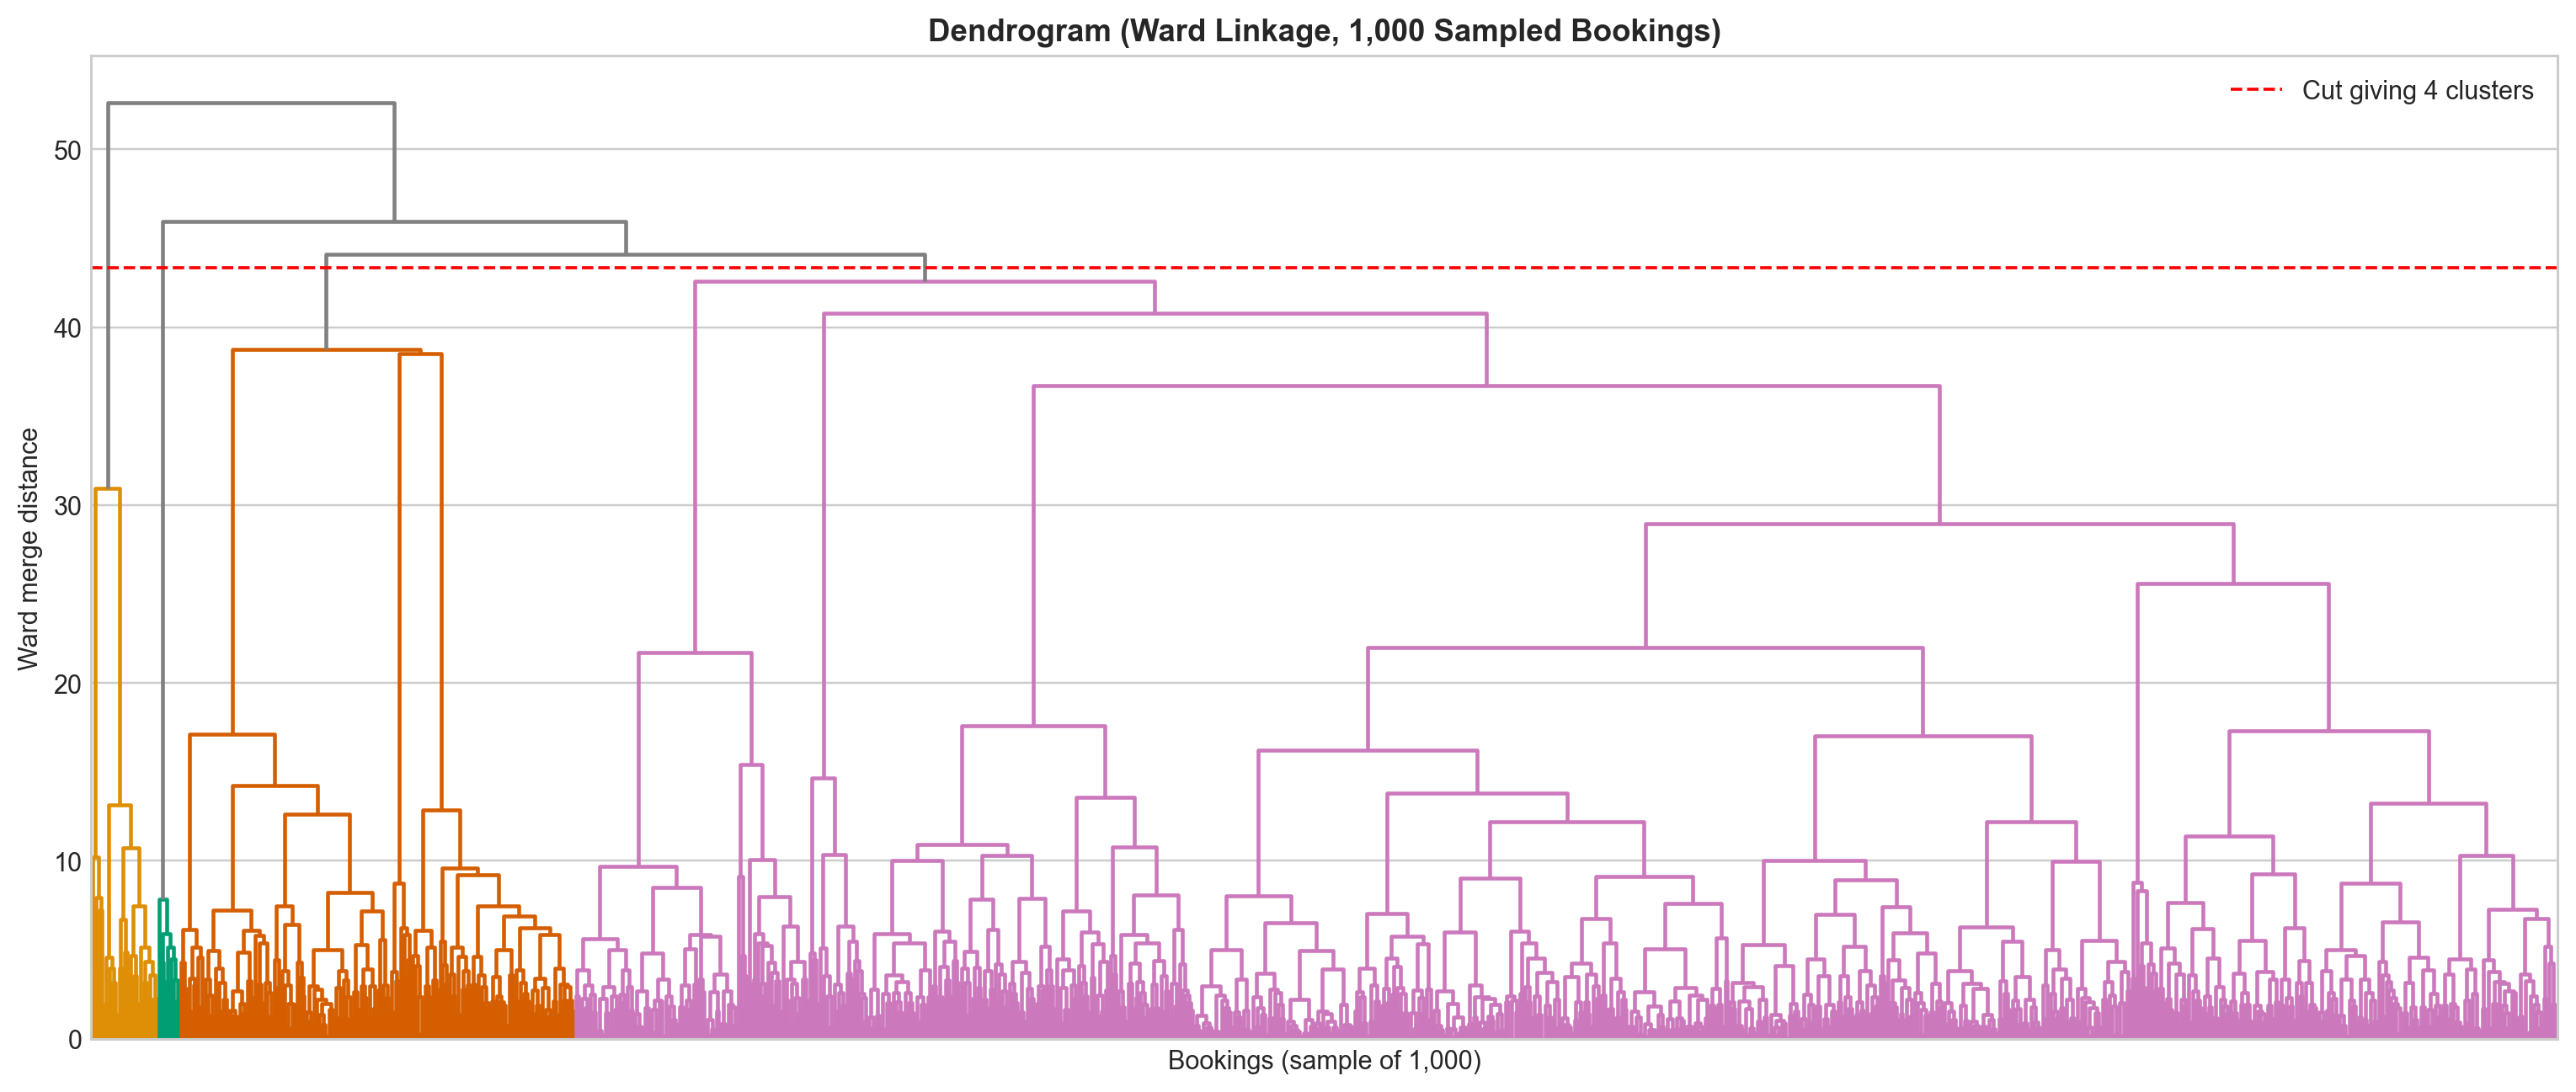

In [16]:
dendro_idx = np.random.RandomState(SEED).choice(len(X_scaled), size=1000, replace=False)
Z = linkage(X_scaled[dendro_idx], method='ward', metric='euclidean')
cut_height = (Z[-3, 2] + Z[-4, 2]) / 2  # cut that leaves 4 clusters

plt.figure(figsize=(14, 6))
dendrogram(Z, no_labels=True, color_threshold=cut_height, above_threshold_color='gray')
plt.axhline(cut_height, color='red', linestyle='--', lw=1.2, label='Cut giving 4 clusters')
plt.title("Dendrogram (Ward Linkage, 1,000 Sampled Bookings)", fontsize=12, fontweight='bold')
plt.xlabel("Bookings (sample of 1,000)")
plt.ylabel("Ward merge distance")
plt.legend()
plt.tight_layout()
plt.show()

**Observation (Dendrogram):** Cutting the Ward tree at the red line leaves 4 clusters. One large branch holds most of the 1,000 sampled bookings and three smaller groups split off at high merge distances (about 44 to 52), so the hierarchy also points to one dominant group plus a few small ones. This is only the tree of the 1,000 sampled bookings, not of the full 15,000.

### Final Agglomerative Model

In [17]:
AGG_LINKAGE, AGG_CLUSTERS = 'ward', 4
agg = AgglomerativeClustering(n_clusters=AGG_CLUSTERS, linkage=AGG_LINKAGE)
labels_agg = agg.fit_predict(X_scaled)

print("Agglomerative cluster sizes:")
display(pd.Series(labels_agg).value_counts().sort_index().to_frame('Bookings').assign(Share=lambda s: (s['Bookings'] / len(labels_agg) * 100).round(1)))

agg_metrics = {
    'Silhouette': silhouette_score(X_scaled, labels_agg),
    'Davies-Bouldin': davies_bouldin_score(X_scaled, labels_agg),
    'Calinski-Harabasz': calinski_harabasz_score(X_scaled, labels_agg)
}
agg_metrics

Agglomerative cluster sizes:


,Bookings,Share
0,13707,91.4
1,980,6.5
2,171,1.1
3,142,0.9


{'Silhouette': 0.45290312466379795,
 'Davies-Bouldin': 1.3782425829596223,
 'Calinski-Harabasz': 1345.4443572536793}

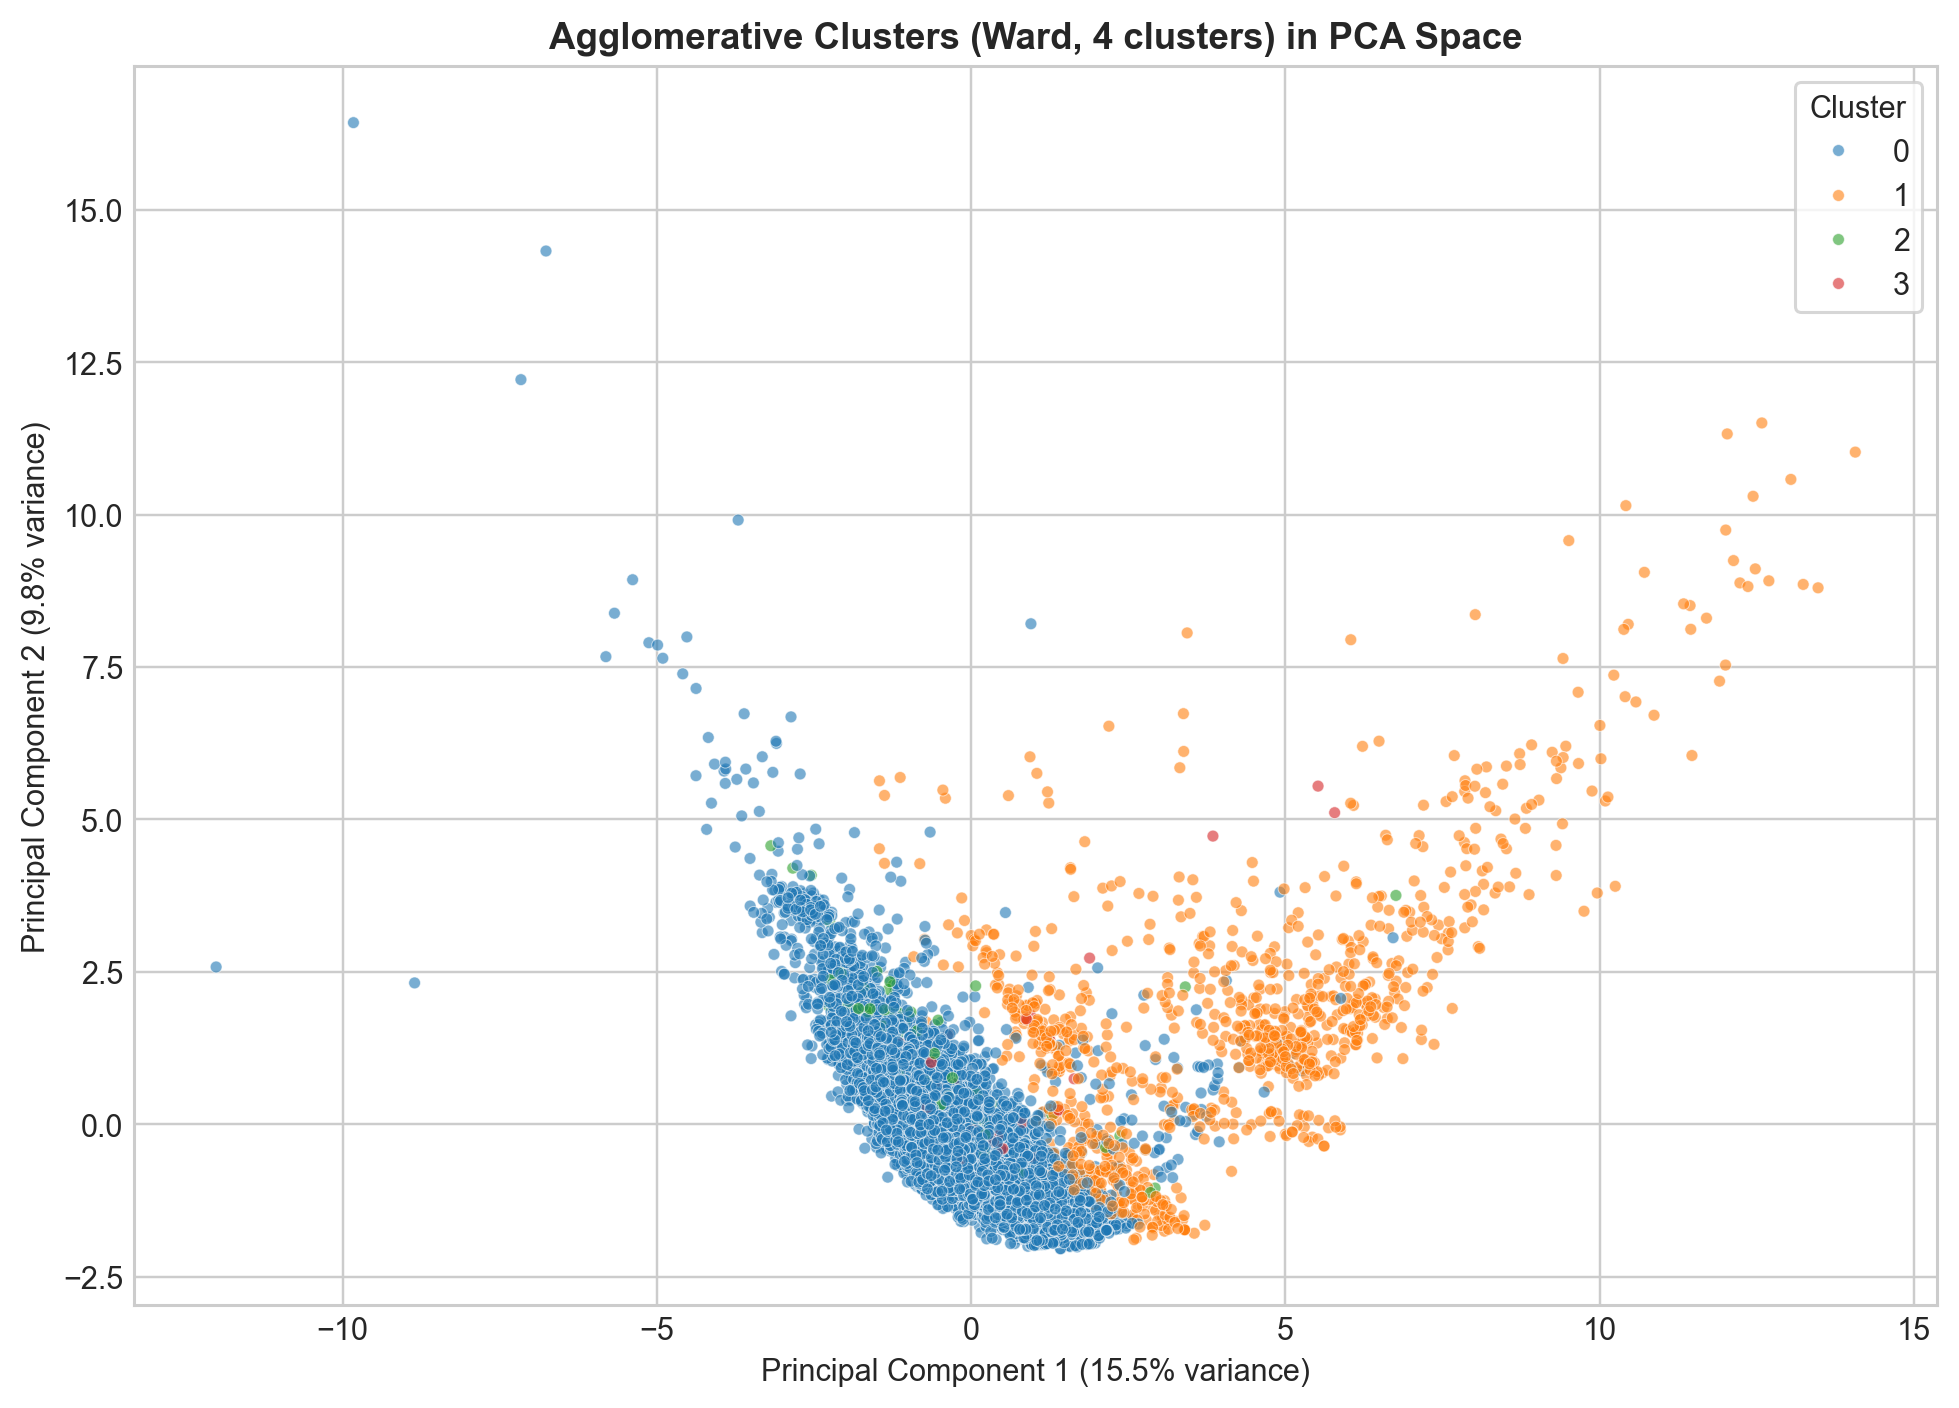

In [18]:
plot_pca_clusters(labels_agg, "Agglomerative Clusters (Ward, 4 clusters) in PCA Space")

**Observation (Agglomerative PCA):** The large cluster 0 sits in the lower left and the 980-booking cluster 1 spreads out to the right, in the same region as the K-Means repeated-guest cluster. Clusters 2 and 3 are small and are scattered inside the large group in these two components.

## Section E - Model Comparison & Cluster Interpretation

### Comparison Table
Both models were fitted and scored on the same 15,000 bookings and the same 48-feature matrix.

In [19]:
def size_summary(labels):
    counts = np.bincount(labels)
    return ", ".join(f"{c:,}" for c in counts)

comparison_df = pd.DataFrame([
    {'Algorithm': 'K-Means', 'Configuration': 'k=4, n_init=10', 'Clusters': K_FINAL,
     **km_metrics, 'Cluster sizes': size_summary(labels_km)},
    {'Algorithm': 'Agglomerative', 'Configuration': f'{AGG_LINKAGE} linkage, {AGG_CLUSTERS} clusters', 'Clusters': AGG_CLUSTERS,
     **agg_metrics, 'Cluster sizes': size_summary(labels_agg)}
])
comparison_df.round(4)

,Algorithm,Configuration,Clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz,Cluster sizes
0,K-Means,"k=4, n_init=10",4,0.2087,1.4673,1469.0309,"1,398, 12,807, 624, 171"
1,Agglomerative,"ward linkage, 4 clusters",4,0.4529,1.3782,1345.4444,"13,707, 980, 171, 142"


**Observation (Comparison):** All numbers come from the same 15,000 bookings. Agglomerative (Ward) has the better Silhouette (0.4529 against 0.2087) and Davies-Bouldin (1.3782 against 1.4673), while K-Means has the better Calinski-Harabasz score (1,469.03 against 1,345.44). So the three metrics do not agree on one winner. Both methods return one dominant cluster (85.4% for K-Means and 91.4% for Agglomerative) and several small ones, so the silhouette difference should not be read as one method finding clearly better groups.

### t-SNE Visualisation
t-SNE is slow on large inputs, so it is run on a random subset of 5,000 of the 15,000 bookings (`random_state=42`). The same embedding is coloured by each algorithm's labels.

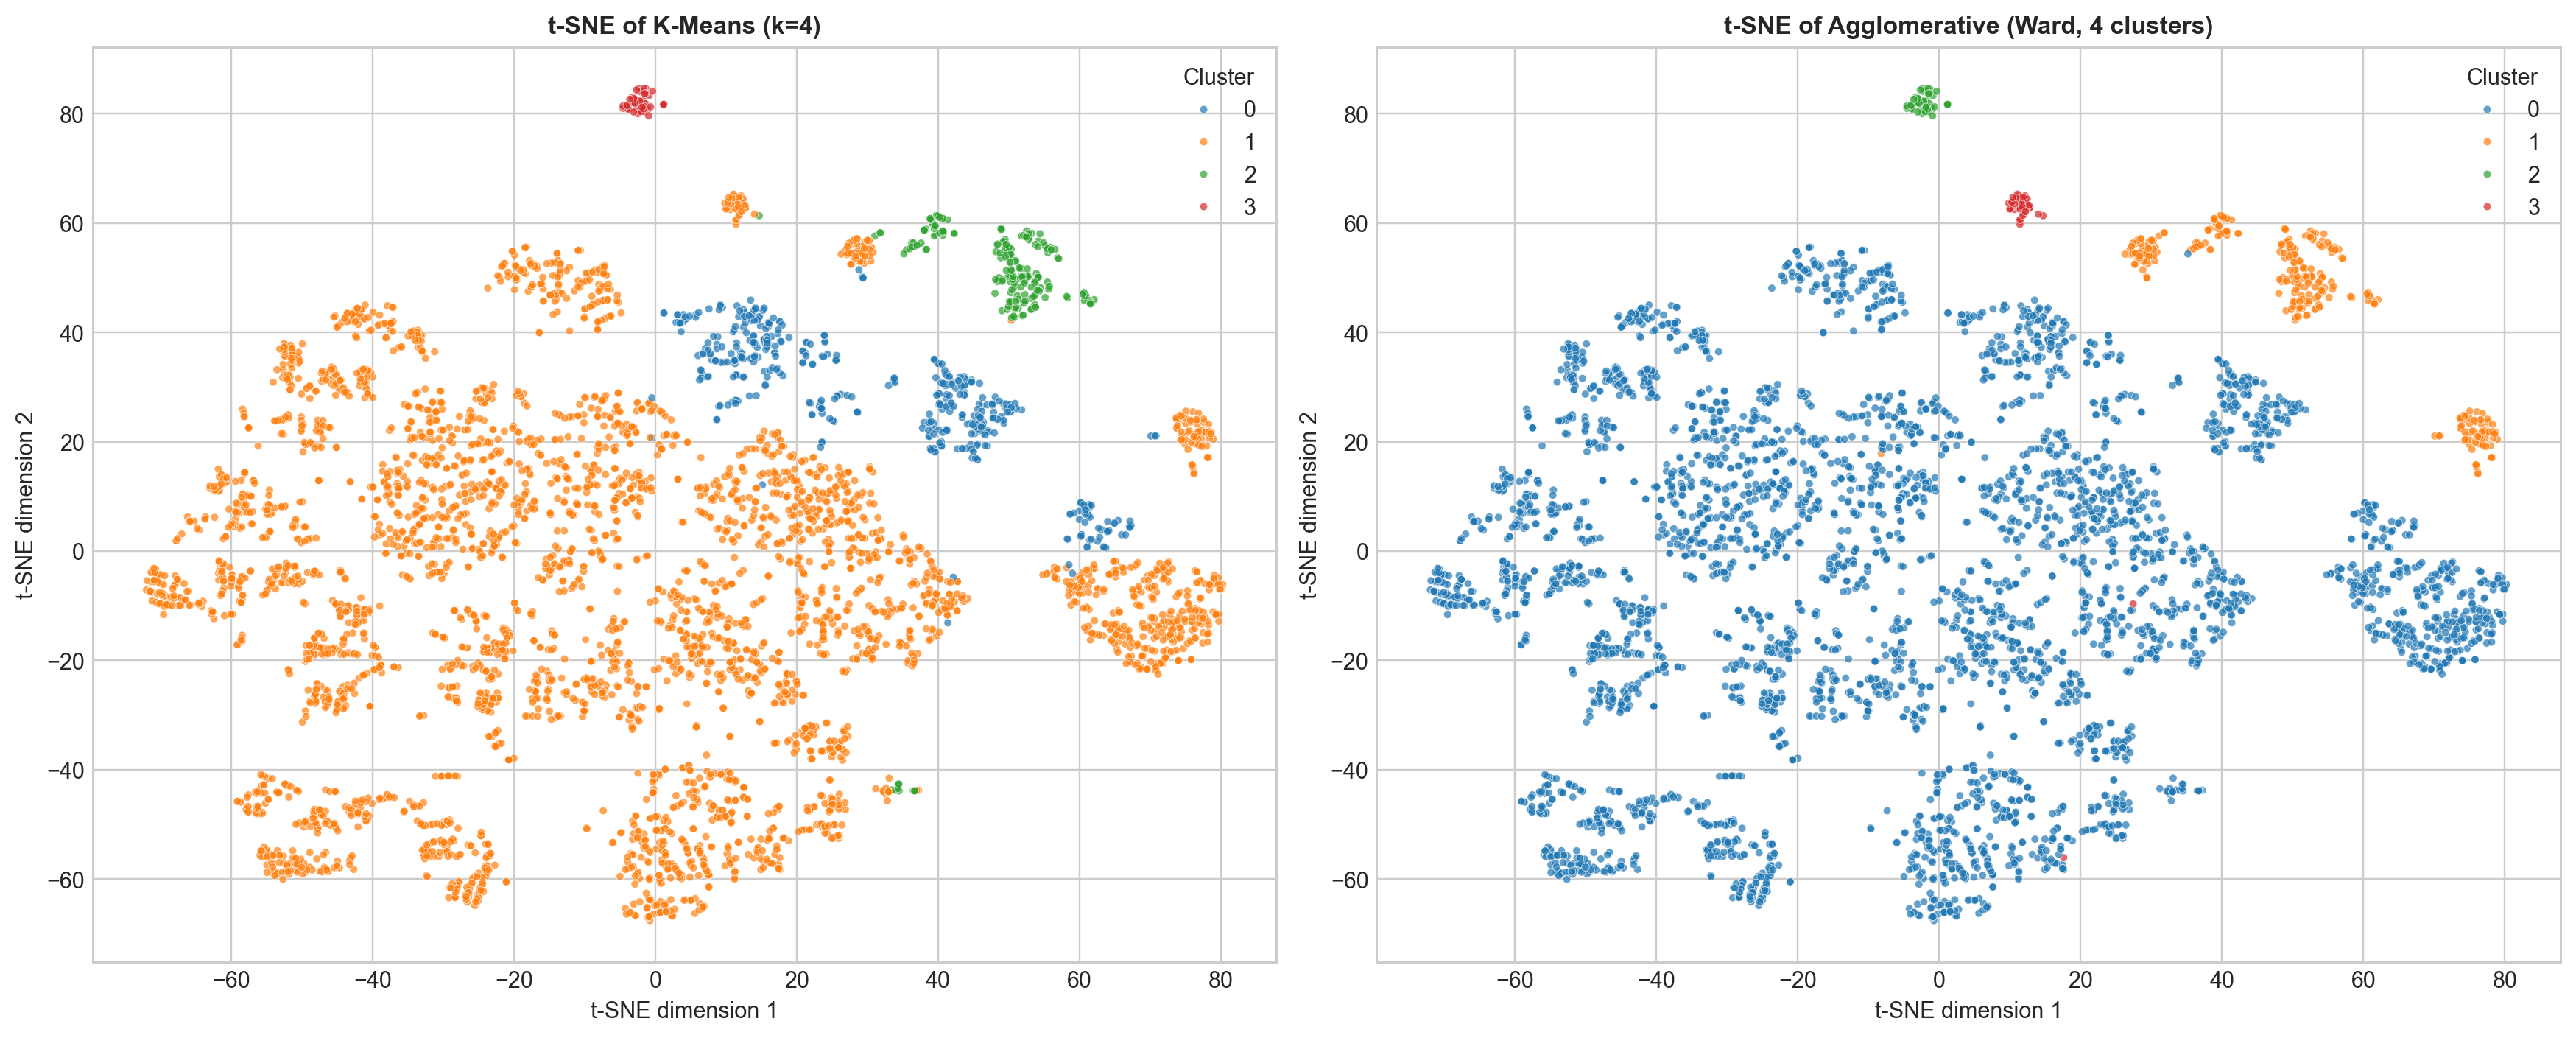

In [20]:
tsne_idx = np.random.RandomState(SEED).choice(len(X_scaled), size=5000, replace=False)
X_tsne = TSNE(n_components=2, perplexity=30, random_state=SEED).fit_transform(X_scaled[tsne_idx])

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, labels, name in [(axes[0], labels_km, 'K-Means (k=4)'), (axes[1], labels_agg, 'Agglomerative (Ward, 4 clusters)')]:
    sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=labels[tsne_idx], palette='tab10', s=12, alpha=0.7, legend='full', ax=ax)
    ax.set_title(f"t-SNE of {name}", fontsize=11, fontweight='bold')
    ax.set_xlabel("t-SNE dimension 1")
    ax.set_ylabel("t-SNE dimension 2")
    ax.legend(title='Cluster')
plt.tight_layout()
plt.show()

**Observation (t-SNE):** On the 5,000-booking subset the embedding breaks into many small islands, and the cluster colours do not follow these islands neatly. The small babies cluster (red in K-Means, green in Agglomerative) is a compact island at the top. The large cluster covers most islands in both methods, which agrees with the PCA plots and the modest silhouette scores.

### Cluster Interpretation
The average value of each feature in every cluster, on the original (unscaled) values of the 15,000 sampled bookings. `is_canceled` was never given to the models; it is shown here only to describe the clusters.

In [21]:
profile_cols = ['lead_time', 'adr', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest',
                'previous_cancellations', 'booking_changes', 'days_in_waiting_list', 'total_of_special_requests', 'is_canceled']
profiled = sample.copy()
profiled['KMeans'] = labels_km
profiled['Agglomerative'] = labels_agg

for name in ['KMeans', 'Agglomerative']:
    print(f"{name}: mean feature values per cluster")
    display(profiled.groupby(name)[profile_cols].mean().round(2).T)

KMeans: mean feature values per cluster


KMeans,0,1,2,3
lead_time,89.32,81.89,18.20,80.22
adr,161.18,103.17,63.55,120.83
stays_in_week_nights,2.86,2.64,1.49,3.00
adults,1.95,1.90,1.36,1.99
children,1.45,0.00,0.03,0.29
babies,0.00,0.00,0.00,1.02
is_repeated_guest,0.00,0.00,0.94,0.01
previous_cancellations,0.01,0.01,0.46,0.01
booking_changes,0.34,0.25,0.28,0.86
days_in_waiting_list,0.00,0.78,0.17,0.00


Agglomerative: mean feature values per cluster


Agglomerative,0,1,2,3
lead_time,81.63,44.24,80.22,160.79
adr,110.98,54.14,120.83,84.64
stays_in_week_nights,2.69,1.66,3.00,2.35
adults,1.91,1.47,1.99,1.69
children,0.15,0.06,0.29,0.00
babies,0.00,0.00,1.02,0.00
is_repeated_guest,0.00,0.60,0.01,0.00
previous_cancellations,0.00,0.44,0.01,0.11
booking_changes,0.26,0.29,0.86,0.50
days_in_waiting_list,0.00,0.00,0.00,70.71


In [22]:
for name in ['KMeans', 'Agglomerative']:
    print(f"{name}: share of each market segment and hotel within a cluster")
    display(pd.crosstab(profiled[name], profiled['market_segment'], normalize='index').round(2))
    display(pd.crosstab(profiled[name], profiled['hotel'], normalize='index').round(2))

print("Agreement between the two clusterings (rows: K-Means, columns: Agglomerative)")
pd.crosstab(profiled['KMeans'], profiled['Agglomerative'])

KMeans: share of each market segment and hotel within a cluster


market_segment,Aviation,Complementary,Corporate,Direct,Groups,Offline TA/TO,Online TA
KMeans,,,,,,,
0,0.00,0.00,0.00,0.18,0.01,0.06,0.75
1,0.00,0.01,0.03,0.12,0.06,0.17,0.60
2,0.02,0.07,0.45,0.23,0.02,0.08,0.14
3,0.00,0.04,0.01,0.34,0.01,0.21,0.40


hotel,City Hotel,Resort Hotel
KMeans,,
0,0.60,0.40
1,0.62,0.38
2,0.46,0.54
3,0.40,0.60


Agglomerative: share of each market segment and hotel within a cluster


market_segment,Aviation,Complementary,Corporate,Direct,Groups,Offline TA/TO,Online TA
Agglomerative,,,,,,,
0,0.00,0.00,0.03,0.13,0.05,0.15,0.63
1,0.01,0.14,0.28,0.18,0.07,0.11,0.22
2,0.00,0.04,0.01,0.34,0.01,0.21,0.40
3,0.00,0.01,0.04,0.00,0.42,0.51,0.02


hotel,City Hotel,Resort Hotel
Agglomerative,,
0,0.62,0.38
1,0.52,0.48
2,0.40,0.60
3,0.87,0.13


Agreement between the two clusterings (rows: K-Means, columns: Agglomerative)


Agglomerative,0,1,2,3
KMeans,,,,
0,1376,22,0,0
1,12304,364,0,139
2,27,594,0,3
3,0,0,171,0


**Observation (Cluster Profiles):** The two methods find some of the same groups.
- **Babies:** K-Means cluster 3 and Agglomerative cluster 2 contain the same 171 bookings, with an average of 1.02 babies and the most special requests (1.43).
- **Repeated guests:** K-Means cluster 2 (624 bookings) is 94% repeated guests with a short lead time (18 days), a low `adr` (63.55) and 45% corporate bookings. Agglomerative cluster 1 (980 bookings) is a looser version of it: 60% repeated guests, `adr` 54.14, and 594 of the 624 K-Means bookings fall in it.
- **Children:** only K-Means finds cluster 0 (1,398 bookings, 1.45 children on average, highest `adr` of 161.18). Ward leaves these bookings in its large cluster.
- **Long waiting list:** only Agglomerative finds cluster 3 (142 bookings) with a lead time of 161 days, 70.7 days on the waiting list, few special requests (0.11), 42% groups and 87% City Hotel.
- **Everything else:** the large cluster in each method (K-Means 12,807, Agglomerative 13,707 bookings) is the typical booking.

`is_canceled` was only used here, after clustering. The cancellation rate differs between clusters (0.09 to 0.37 for K-Means, 0.22 to 0.35 for Agglomerative), but this notebook does not predict cancellations and these numbers only describe the groups that were found.

### Summary
- **Data:** 119,390 bookings, reduced to 87,229 after removing duplicates and invalid rows; a 15,000-booking random sample and 48 features (14 numeric, 34 one-hot) were used for both models.
- **K-Means:** the elbow curve shows no sharp elbow, so $k=4$ was chosen from the silhouette and Davies-Bouldin scores; it gives Silhouette 0.2087, Davies-Bouldin 1.4673 and Calinski-Harabasz 1,469.03.
- **Agglomerative:** Ward linkage with 4 clusters gives Silhouette 0.4529, Davies-Bouldin 1.3782 and Calinski-Harabasz 1,345.44; complete and average linkage were rejected because they isolate single bookings.
- **Limits:** both solutions are dominated by one large cluster, the silhouette scores are modest, and the dendrogram and t-SNE use subsets of 1,000 and 5,000 bookings.